In [79]:
import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt

# Load MODIS data for Ross island

In [80]:
# tensor format so leave as is
modis_ross = torch.load("/Users/kim.bente/DATA/MODIS/MODIS_regional/moa125_2014_hp1_v01_ross_island_with_grid.pt", weights_only = False)

# Replace zeroes with NaN for ocean mask (last dim is values)
modis_ross[2][modis_ross[2] == 0] = np.nan
modis_ross[2]

tensor([[16016., 16016., 16024.,  ..., 14608., 14512., 14352.],
        [16024., 16024., 16024.,  ..., 14704., 14600., 14400.],
        [16032., 16024., 16024.,  ..., 14832., 14712., 14464.],
        ...,
        [   nan,    nan,    nan,  ...,    nan,    nan,    nan],
        [   nan,    nan,    nan,  ...,    nan,    nan,    nan],
        [   nan,    nan,    nan,  ...,    nan,    nan,    nan]])

# Define boundries and load velocity data

In [81]:
# import region bounds
from regions import ROSS_ISLAND_BOUNDS

# assign region bounds
x_min = ROSS_ISLAND_BOUNDS["x_min"]
x_max = ROSS_ISLAND_BOUNDS["x_max"]
y_min = ROSS_ISLAND_BOUNDS["y_min"]
y_max = ROSS_ISLAND_BOUNDS["y_max"]

In [82]:
path_to_phase_based_ice_vel = "/Users/kim.bente/DATA/ice_velocity/NSIDC-0484_2-20261004_220442/antarctica_ice_velocity_450m_v2.nc"

ice_vel_phase = xr.open_dataset(path_to_phase_based_ice_vel)
# print(ice_vel_phase)  # shows variables, dimensions and coordinates

# Subset for Ross Island region
ice_vel_phase_ross_island = ice_vel_phase.sel(
    x = slice(x_min, x_max),
    y = slice(y_max, y_min) # Note: y_max and y_min are reversed because y decreases southward in polar stereographic coordinates
)

# Mask out ocean in torch tensor

In [ ]:
# Interpolate 2.3 M points
vel_at_points = ice_vel_phase_ross_island[["VX", "VY"]].interp(
    x = ("points", modis_ross[0].numpy().ravel()),
    y = ("points", modis_ross[1].numpy().ravel()),
    method = "linear",
)

# Reshape the interpolated values back to the original grid shape
vel_at_points_reshaped = vel_at_points.to_array().values.reshape(modis_ross[0].shape[0], modis_ross[0].shape[1], 2)
vel_at_points_reshaped.shape  # should be (n_lat, n_lon, 2)

(1440, 1600, 2)

In [ ]:
# same as unqueeze
vel_at_points_reshaped = np.expand_dims(vel_at_points.VX.values.reshape(modis_ross[0].shape[0], modis_ross[0].shape[1]), -1)
np.isnan(vel_at_points_reshaped).sum()

np.int64(863928)

In [105]:
print("Number of interpolated velocity points that are NaN:", np.isnan(vel_at_points_reshaped[:, :, 0]).sum())  # should be 2.3 M points
# about 1/3rd of the points are NaN because they are outside the ice velocity data coverage
print("Number of MODIS points that are NaN:", np.isnan(modis_ross[2]).sum().item())  # less... 500k 

Number of interpolated velocity points that are NaN: 863928
Number of MODIS points that are NaN: 490563


/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_68854/668866279.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print("Number of MODIS points that are NaN:", np.isnan(modis_ross[2]).sum().item())  # less... 500k


In [106]:
modis_ross_extended = torch.cat([modis_ross, modis_ross[2].unsqueeze(0)], dim = 0)
modis_ross_extended.shape

torch.Size([4, 1440, 1600])

In [107]:
print(torch.tensor(vel_at_points_reshaped[:, :, 0]).shape)
print(modis_ross_extended[3].shape)

torch.Size([1440, 1600])
torch.Size([1440, 1600])


In [108]:
# True where either velocity component is NaN
vel_nan = torch.isnan(torch.as_tensor(vel_at_points_reshaped[:, :, 0]))
vel_nan.shape
# vel_nan.sum()

torch.Size([1440, 1600])

In [109]:
modis_ross_extended[-1, vel_nan] = float("nan")
print(modis_ross_extended[3].isnan().sum())

tensor(863928)


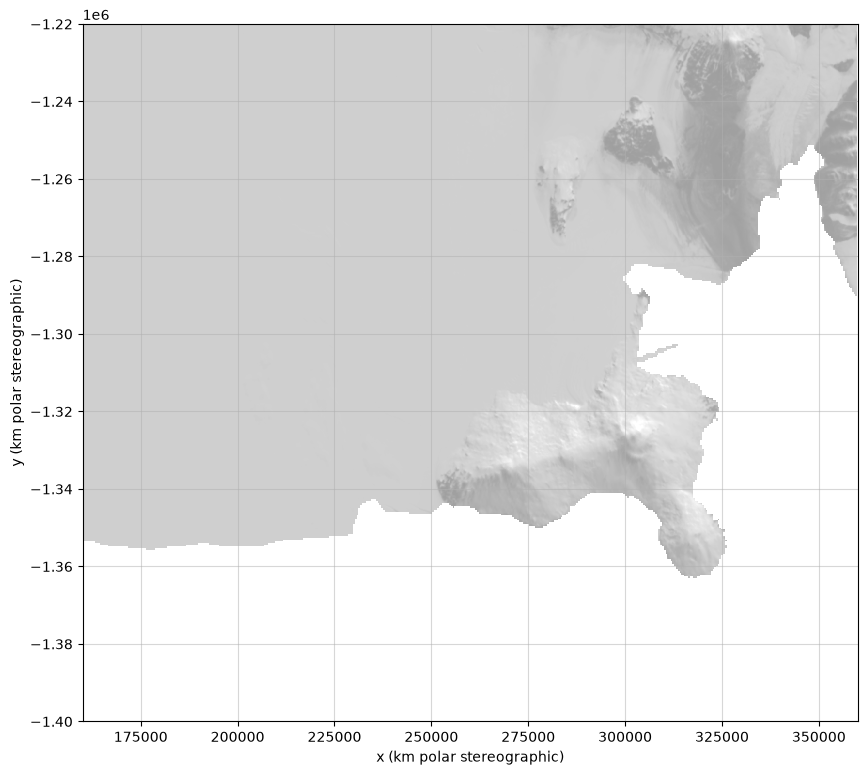

In [112]:
fig, ax = plt.subplots(figsize = (10, 10))

ax.pcolormesh(
    modis_ross_extended[0],
    modis_ross_extended[1], 
    modis_ross_extended[3],
    cmap = "gray",
    # softer greys
    vmin = -30_000, 
    vmax = 30_000,
    # as less saturated background
    alpha = 0.8,
    zorder = 0,
)

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [111]:
torch.save(modis_ross_extended, "/Users/kim.bente/DATA/MODIS/MODIS_regional/moa125_2014_hp1_v01_ross_island_with_grid_no_ocean.pt")